# Smart Irrigation — ML Decision Policy (FAO-56 proxy labels)

**Статус: дослідницький backtest, НЕ польова валідація.**

Задача: навчити `LightGBMClassifier` відтворювати **попередні рішення фізичної моделі** на наявних історичних даних двох полів. Мітки отримано з FAO-56-style правила з **припущеними** FC/PWP, фазами росту та кореневою глибиною, а не зі справжніх журналів поливу. Метрики нижче — **узгодженість із proxy-мітками**, а не правильність поливу. Усі знімки історичні (до жовтня 2025 р.).

**Класи:** `no_action`, `monitor`, `review_irrigation`. Події `insufficient_data` та `no_action_out_of_season` залишаються в детермінованому шарі (їх не перекодовуємо як негативні мітки). `postpone_review` можливий лише за наявності реального прогнозу, виданого до моменту рішення; такого прогнозу у файлі немає.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'outputs').exists() and (ROOT / 'smart_irrigation_ml' / 'outputs').exists():
    ROOT = ROOT / 'smart_irrigation_ml'
OUT = ROOT / 'outputs'
print('Project:', ROOT.resolve())
required = ['decision_prototype_daily.csv','decision_policy_summary.json','decision_policy_walkforward_metrics.csv',
            'decision_policy_walkforward_predictions.csv','decision_policy_per_field_metrics.csv']
assert all((OUT/f).exists() for f in required), 'Run train_decision_policy.py first.'
summary=json.loads((OUT/'decision_policy_summary.json').read_text())
teacher=pd.read_csv(OUT/'decision_prototype_daily.csv',parse_dates=['decision_timestamp'])
metrics=pd.read_csv(OUT/'decision_policy_walkforward_metrics.csv')
pred=pd.read_csv(OUT/'decision_policy_walkforward_predictions.csv',parse_dates=['decision_timestamp'])
field_metrics=pd.read_csv(OUT/'decision_policy_per_field_metrics.csv')
print('Physics teacher cases:',len(teacher),' / ML-labeled cases:',summary['n_labeled_training_rows'])

Project: /mnt/data/smart_irrigation_ml
Physics teacher cases: 1160  / ML-labeled cases: 641


## 1. Процес і джерела міток

1. Погодинні телеметричні дані → causal daily snapshot о 06:00 (сенсори, SMAP, попередні 24 години ET₀).
2. Physics teacher (FAO-56-style) → попередні action labels із припущеними коефіцієнтами, з урахуванням віку супутникових даних.
3. Feature engineering із даних, **доступних на момент рішення**: SMAP, ET₀ за минулу добу, Kc, історичні лаги, минулі опади, quality flags, батарея, культура/поле.
4. LightGBM → три класи та ймовірності; поріг `review_irrigation` оптимізовано на **частині 2024**, а оцінено на **тестових вікнах 2025**.
5. Фінальний гібрид → фізична модель формує основну пораду; якщо ML не згодна чи параметри ґрунту непевні, додається **manual review**, а не автоматичне керування.

**Виключено leakage:** відсутні у фічах `depletion_over_raw`, `depletion_mm`, `raw_mm`, сам teacher action, майбутня погода та майбутні сенсорні показники. Рядки з великими часовими прогалинами не інтерполюються.


In [2]:
print('All historical rule recommendations:')
display(teacher.recommendation.value_counts().rename_axis('rule_action').reset_index(name='days'))
print('Training distribution per field:')
display(pd.read_csv(OUT/'decision_policy_class_counts_by_field.csv').pivot(index='field_id',columns='proxy_action_from_assumed_FAO56_rule_NOT_GROUND_TRUTH',values='n').fillna(0).astype(int))

All historical rule recommendations:


,rule_action,days
0,no_action_out_of_season,497
1,no_action,339
2,monitor,241
3,review_irrigation,61
4,insufficient_data,22


Training distribution per field:


proxy_action_from_assumed_FAO56_rule_NOT_GROUND_TRUTH,monitor,no_action,review_irrigation
field_id,,,
field_3334,52,261,0
field_3335,189,78,61


## 2. Часова валідація

**Тестові часові вікна:** 2025-06-01→2025-07-15, 2025-07-15→2025-08-15, 2025-08-15→2025-10-06. Навчання відбувається виключно на датах до старту тесту із gap у 1 добу. Поріг для ризикового класу вибрано із F₂ на September 2024, після навчання на більш ранніх даних.

**Увага:** лише 9 позитивних випадків в inner-validation 2024 р., тому вибраний поріг може бути нестабільним.


In [3]:
cols=['fold','n_train','n','n_review_true_proxy','risk_threshold_from_2024_inner_validation',
      'agreement_macro_F1','review_recall_proxy','review_precision_proxy',
      'review_F2_proxy','review_false_negatives_proxy','review_PR_AUC_proxy']
display(metrics[cols].round(3))
display(pd.read_csv(OUT/'decision_policy_inner_threshold_audit.csv'))

,fold,n_train,n,n_review_true_proxy,risk_threshold_from_2024_inner_validation,agreement_macro_F1,review_recall_proxy,review_precision_proxy,review_F2_proxy,review_false_negatives_proxy,review_PR_AUC_proxy
0,1,395,88,11,0.9,0.549,0.000,NaN,0.000,11,0.100
1,2,483,62,16,0.9,0.812,0.938,0.750,0.893,1,0.834
2,3,545,94,10,0.9,0.548,0.900,0.391,0.714,1,0.885


,fold,inner_train_n,inner_validation_n,inner_train_latest,inner_validation_earliest,inner_validation_end_exclusive,criterion,threshold,inner_f2,inner_pos_n,inner_selected_alerts
0,1,246,60,2024-08-30 06:00:00,2024-09-01 06:00:00,2024-10-01 00:00:00,"F2 positive=review_irrigation, threshold tuned...",0.9,1.0,9,9
1,2,246,60,2024-08-30 06:00:00,2024-09-01 06:00:00,2024-10-01 00:00:00,"F2 positive=review_irrigation, threshold tuned...",0.9,1.0,9,9
2,3,246,60,2024-08-30 06:00:00,2024-09-01 06:00:00,2024-10-01 00:00:00,"F2 positive=review_irrigation, threshold tuned...",0.9,1.0,9,9


## 3. Підсумок позавибіркового узгодження

Наведені числові оцінки відповідають **тільки відкладеним часовим прогнозам**, не фінальній моделі після донавчання на всьому наборі. На відміну від продуктивної політики, це метрики **відтворення rule-based proxy labels**, не точність рекомендацій для рослин.


,Test samples,Proxy review instances,Macro F1 (vs teacher),Review Recall (vs teacher),Review Precision (vs teacher),Review F2 (vs teacher),False negatives vs teacher,PR-AUC vs teacher
0,244,37,0.687,0.649,0.558,0.628,13,0.587


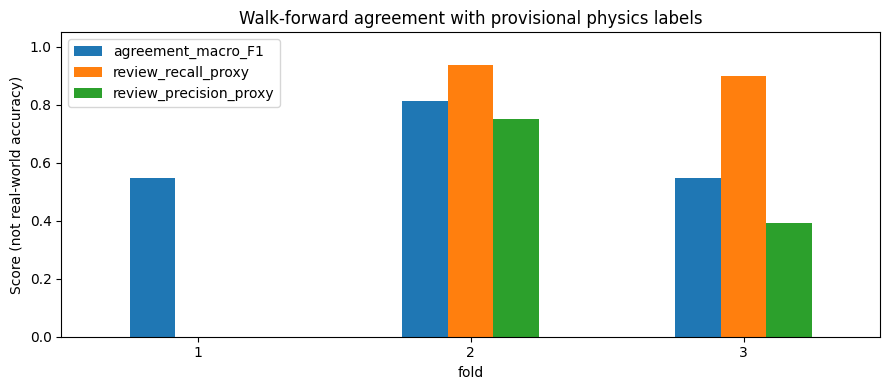

In [4]:
s=summary['pooled_outer_test_agreement_WITH_TEACHER_NOT_REAL_WORLD']
display(pd.DataFrame([{
    'Test samples':s['n'],'Proxy review instances':s['n_review_true_proxy'],
    'Macro F1 (vs teacher)':round(s['agreement_macro_F1'],3),
    'Review Recall (vs teacher)':round(s['review_recall_proxy'],3),
    'Review Precision (vs teacher)':round(s['review_precision_proxy'],3),
    'Review F2 (vs teacher)':round(s['review_F2_proxy'],3),
    'False negatives vs teacher':s['review_false_negatives_proxy'],
    'PR-AUC vs teacher':round(s['review_PR_AUC_proxy'],3),
}]))
fig,ax=plt.subplots(figsize=(9,4))
metrics.set_index('fold')[['agreement_macro_F1','review_recall_proxy','review_precision_proxy']].plot.bar(ax=ax,rot=0)
ax.set_ylim(0,1.05);ax.set_title('Walk-forward agreement with provisional physics labels')
ax.set_ylabel('Score (not real-world accuracy)')
plt.tight_layout();plt.show()

## 4. Матриця помилок: teacher vs model

Переплутані `monitor` та `review_irrigation` означають розбіжність між моделлю й фізичним правилом. Це не доводить, що полив був неправильний. Хибнонегативні тут — **пропущені сигнали teacher**, а не пропущена реальна потреба рослини.


,ml_no_action,ml_monitor,ml_review_irrigation
teacher_no_action,63,27,0
teacher_monitor,13,85,19
teacher_review_irrigation,0,13,24


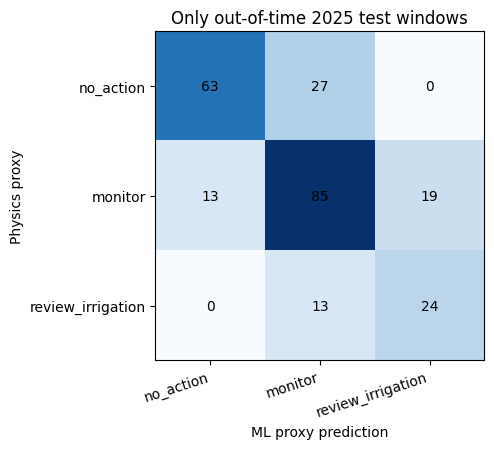

In [5]:
cm=pd.read_csv(OUT/'decision_policy_confusion_matrix.csv',index_col=0)
display(cm)
fig, ax=plt.subplots(figsize=(8,4.6));im=ax.imshow(cm.to_numpy(),cmap='Blues')
for i in range(3):
    for j in range(3): ax.text(j,i,str(cm.iloc[i,j]),ha='center',va='center')
ax.set_xticks(range(3),['no_action','monitor','review_irrigation'],rotation=18,ha='right')
ax.set_yticks(range(3),['no_action','monitor','review_irrigation'])
ax.set_ylabel('Physics proxy');ax.set_xlabel('ML proxy prediction')
ax.set_title('Only out-of-time 2025 test windows');plt.tight_layout();plt.show()

## 5. Критична помилка: позитивні приклади з одного поля

На `field_3334` physics teacher не відмітив жодної потреби review. Оскільки позитивний клас є лише на `field_3335`, transfer learning на нові поля не перевірено. Показник recall за відсутності позитивів слід виводити як `NaN`, а не як 0 або 100%.


In [6]:
display(field_metrics[['field_id','n','n_review_true_proxy','review_recall_proxy',
        'review_precision_proxy','agreement_macro_F1','review_false_negatives_proxy']].round(3))
errors=pred[pred.is_proxy_false_negative_review]
print('False-negative teacher alerts by held-out fold:',errors.groupby('fold').size().to_dict())
display(errors[['decision_timestamp','field_id','fold','smap_theta_rootzone_m3m3',
                'ml_probability_review_irrigation','ml_predicted_proxy_action']].head(12))

,field_id,n,n_review_true_proxy,review_recall_proxy,review_precision_proxy,agreement_macro_F1,review_false_negatives_proxy
0,field_3334,122,0,NaN,NaN,0.431,0
1,field_3335,122,37,0.649,0.558,0.463,13


False-negative teacher alerts by held-out fold: {1: 11, 2: 1, 3: 1}


,decision_timestamp,field_id,fold,smap_theta_rootzone_m3m3,ml_probability_review_irrigation,ml_predicted_proxy_action
51,2025-06-26 06:00:00,field_3335,1,0.188902,0.003184,monitor
53,2025-06-27 06:00:00,field_3335,1,0.189656,0.003184,monitor
59,2025-06-30 06:00:00,field_3335,1,0.187538,0.003184,monitor
61,2025-07-01 06:00:00,field_3335,1,0.186828,0.003184,monitor
63,2025-07-02 06:00:00,field_3335,1,0.185474,0.003184,monitor
65,2025-07-03 06:00:00,field_3335,1,0.183933,0.003184,monitor
67,2025-07-04 06:00:00,field_3335,1,0.183365,0.003184,monitor
69,2025-07-05 06:00:00,field_3335,1,0.181909,0.003184,monitor
71,2025-07-06 06:00:00,field_3335,1,0.181400,0.003216,monitor
73,2025-07-07 06:00:00,field_3335,1,0.180981,0.003216,monitor


## 6. Аналіз невизначеності FAO-56

**Усі 61 позитивні сигнали** `review_irrigation` мають `assumption_sensitive` за широкими діапазонами FC/PWP. Немає достовірного польового калібрування, реєстру поливів та дат посіву. Фізичну рекомендацію не можна розглядати як істинну мітку для агрономії.


In [7]:
positives=teacher[teacher.recommendation.eq('review_irrigation')]
print('Review candidates:',len(positives))
print('Sensitive-to-assumptions review candidates:',int(positives.assumption_robustness.eq('assumption_sensitive').sum()))
display(pd.crosstab(teacher.recommendation,teacher.assumption_robustness))

Review candidates: 61
Sensitive-to-assumptions review candidates: 61


assumption_robustness,assumption_sensitive,not_assessed,wet_all_assumptions
recommendation,,,
insufficient_data,0,22,0
monitor,241,0,0
no_action,0,0,339
no_action_out_of_season,0,497,0
review_irrigation,61,0,0


## 7. Гібридне рішення

Правило FAO-56-style залишається **основним і прозорим decision engine**. ML-оцінка — допоміжний прогноз, навчений на виході правила. При розбіжності показуємо `manual_review_model_disagrees`; при непевності фізичних параметрів — `manual_review_soil_uncertainty`; при відсутності коректних даних — `insufficient_data`. Результат не запускає насос і не видає виробничу рекомендацію поливу.

**Не інтерпретуйте `hybrid_advisory_historical.csv` як backtest ML:** фінальна ML-модель в ньому може прогнозувати на рядках, що використовувалися для її власного навчання. Єдина незалежна ML-оцінка — `decision_policy_walkforward_predictions.csv`.


In [8]:
hybrid=pd.read_csv(OUT/'hybrid_advisory_historical.csv',parse_dates=['decision_timestamp'])
display(hybrid.hybrid_advisory_status.value_counts().rename_axis('status').reset_index(name='historical_days'))
display(hybrid[hybrid.physics_rule_action.eq('review_irrigation')][[
 'field_id','decision_timestamp','physics_rule_action','ml_proxy_action',
 'hybrid_advisory_status']].head(8))

,status,historical_days
0,out_of_assumed_season,497
1,rule_and_model_agree_unvalidated,339
2,manual_review_soil_uncertainty,301
3,insufficient_data,22
4,manual_review_model_disagrees,1


,field_id,decision_timestamp,physics_rule_action,ml_proxy_action,hybrid_advisory_status
734,field_3335,2024-08-13 06:00:00,review_irrigation,review_irrigation,manual_review_soil_uncertainty
735,field_3335,2024-08-14 06:00:00,review_irrigation,review_irrigation,manual_review_soil_uncertainty
736,field_3335,2024-08-15 06:00:00,review_irrigation,review_irrigation,manual_review_soil_uncertainty
737,field_3335,2024-08-16 06:00:00,review_irrigation,review_irrigation,manual_review_soil_uncertainty
738,field_3335,2024-08-17 06:00:00,review_irrigation,review_irrigation,manual_review_soil_uncertainty
740,field_3335,2024-08-19 06:00:00,review_irrigation,review_irrigation,manual_review_soil_uncertainty
741,field_3335,2024-08-20 06:00:00,review_irrigation,review_irrigation,manual_review_soil_uncertainty
742,field_3335,2024-08-21 06:00:00,review_irrigation,review_irrigation,manual_review_soil_uncertainty


## 8. Forecasting залишається окремою задачею

У попередньому модулі `Smart_Irrigation_ML.ipynb` перевірялися LightGBM для `sm_clean(t+24/72/168h)` проти persistence. Найкращий ML RMSE не перевершив persistence на об'єднаних відкладених прогнозах; отже для фізичного decision engine не треба підміняти поточний SMAP прогнозом із недоведеною перевагою.


In [9]:
fpath=OUT/'forecast_pooled_comparison.csv'
if fpath.exists(): display(pd.read_csv(fpath))
else: print('Forecast results not found, run ml_pipeline.py')

,horizon_h,model,MAE,RMSE,n
0,24,persistence,2.358781,7.145184,5153
1,24,lightgbm_delta,4.673919,9.504059,5153
2,24,lightgbm_level,4.598014,9.190999,5153
3,72,persistence,6.218609,12.797614,4686
4,72,lightgbm_delta,9.352607,15.334593,4686
5,72,lightgbm_level,10.077953,16.776042,4686
6,168,persistence,12.717984,20.650205,4176
7,168,lightgbm_delta,14.258867,20.879356,4176
8,168,lightgbm_level,15.840786,23.104870,4176


## 9. Відтворення

Рекомендовано запустити з кореня папки `smart_irrigation_ml`:

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt
mkdir -p input
cp /path/to/irrigation_ml_dataset.csv input/
python ml_pipeline.py --data input/irrigation_ml_dataset.csv
python irrigation_recommendations.py --data input/irrigation_ml_dataset.csv
python train_decision_policy.py --data input/irrigation_ml_dataset.csv --teacher outputs/decision_prototype_daily.csv
python predict_hybrid_policy.py --data input/irrigation_ml_dataset.csv
python -m unittest discover -s tests -v
```

**Готовність:** дослідницький алгоритм відтворюваний, 13 тестів пройшли. **Не готово:** доказ правильності польових рекомендацій, узагальнення на інші поля, реальні прогнози погоди, активація систем зрошення.
